# Week 8- START

In [8]:
#Additional imports for Week 8

import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingClassifier, StackingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_val_predict
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Hide neural network convergence warnings
warnings.filterwarnings("ignore", category=ConvergenceWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)

# Load the Week 5 training data (27-feature reduced set)
PROCESSED_DIR = Path("../data/processed")
reduced8 = pd.read_csv(PROCESSED_DIR / "train_model_reduced.csv")
X8 = reduced8.drop(columns="Response")
y8 = reduced8["Response"]
print("Features:", X8.shape[1], "| Customers:", len(X8), "| Responders:", int(y8.sum()), f"({y8.mean():.1%})")

# Same 15 train/validation splits as Weeks 6 and 7 (5 folds x 3 repeats, seed 42)
splits8 = list(RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42).split(X8, y8))
metrics8 = ["PR-AUC", "ROC-AUC", "Precision", "Recall", "F1"]

def evaluate8(model, X_data, name):
    """Train on each training fold and score on the training and validation folds.
    Precision, recall, and F1 use a 0.5 cutoff."""
    rows = []
    for fold, (tr, va) in enumerate(splits8):
        fitted = clone(model).fit(X_data.iloc[tr], y8.iloc[tr])
        for part, idx in (("Training", tr), ("Validation", va)):
            prob = fitted.predict_proba(X_data.iloc[idx])[:, 1]
            true = y8.iloc[idx]
            rows.append({"model": name, "fold": fold, "set": part,
                         "PR-AUC": average_precision_score(true, prob),
                         "ROC-AUC": roc_auc_score(true, prob),
                         "Precision": precision_score(true, prob >= 0.5, zero_division=0),
                         "Recall": recall_score(true, prob >= 0.5),
                         "F1": f1_score(true, prob >= 0.5)})
    return pd.DataFrame(rows)

Features: 27 | Customers: 1608 | Responders: 234 (14.6%)


In [10]:
# Base models with the tuned settings from Week 6 (logistic regression, gradient boosting)
# and Week 7 (neural network Variation 1)
base_models = {
    "lr": LogisticRegression(C=3, penalty="l2", solver="liblinear", max_iter=5000),
    "gb": GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=2,
                                     subsample=0.8, random_state=42),
    "mlp": make_pipeline(StandardScaler(),
                         MLPClassifier(hidden_layer_sizes=(8,), alpha=3.0, activation="relu",
                                       solver="adam", learning_rate_init=0.001,
                                       max_iter=500, random_state=42)),
}
base_labels = {"lr": "Logistic regression", "gb": "Gradient boosting", "mlp": "Neural network"}

In [11]:
# Cross-validated probabilities from each base model
oof_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
base_oof = pd.DataFrame({base_labels[k]: cross_val_predict(m, X8, y8, cv=oof_cv, method="predict_proba")[:, 1]
                         for k, m in base_models.items()})

# PR-AUC of each base model
print("PR-AUC of each base model (cross-validated predictions):")
print(base_oof.apply(lambda p: average_precision_score(y8, p)).round(3).to_string())

# Spearman correlation between the base models' rankings
print("\nSpearman correlation between base model rankings:")
print(base_oof.corr(method="spearman").round(3).to_string())

# Share of the top 270 customers that each pair of models has in common
top_n = 270
top_sets = {name: set(p.nlargest(top_n).index) for name, p in base_oof.items()}
names = list(top_sets)
print(f"\nShare of top {top_n} customers that two models have in common:")
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        shared = len(top_sets[names[i]] & top_sets[names[j]]) / top_n
        print(f"  {names[i]} vs {names[j]}: {shared:.1%}")

/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalt

PR-AUC of each base model (cross-validated predictions):
Logistic regression    0.724
Gradient boosting      0.695
Neural network         0.721

Spearman correlation between base model rankings:
                     Logistic regression  Gradient boosting  Neural network
Logistic regression                1.000              0.877           0.975
Gradient boosting                  0.877              1.000           0.896
Neural network                     0.975              0.896           1.000

Share of top 270 customers that two models have in common:
  Logistic regression vs Gradient boosting: 76.3%
  Logistic regression vs Neural network: 91.5%
  Gradient boosting vs Neural network: 78.1%


### Stacking variations

| Hyperparameter | Variation 1 | Variation 2 | Variation 3 |
|---|---|---|---|
| `estimators` | LR + NN | LR + GB + NN | LR + GB + NN |
| `passthrough` | False | False | True |
| Meta-model `C` | 1.0 | 1.0 | 0.1 |

In [12]:
# Build a stacking model from the chosen base models, passthrough setting, and meta-model C.
# The meta-model is a scaled logistic regression trained on inner 5-fold predictions.
def make_stack(base_keys, passthrough, meta_C):
    return StackingClassifier(
        estimators=[(k, base_models[k]) for k in base_keys],
        final_estimator=make_pipeline(StandardScaler(),
                                      LogisticRegression(C=meta_C, max_iter=5000)),
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
        stack_method="predict_proba",
        passthrough=passthrough,
        n_jobs=-1)

# The three variations
variations8 = {"Variation 1": make_stack(["lr", "mlp"], passthrough=False, meta_C=1.0),
               "Variation 2": make_stack(["lr", "gb", "mlp"], passthrough=False, meta_C=1.0),
               "Variation 3": make_stack(["lr", "gb", "mlp"], passthrough=True, meta_C=0.1)}
reference_name8 = "Logistic regression (tuned, Week 6)"
res8 = {}

# Table of each variation's settings and number of meta-model inputs
settings8 = pd.DataFrame({
    name: {"base models": " + ".join(base_labels[k] for k, _ in s.estimators),
           "passthrough": s.passthrough,
           "meta-model C": s.final_estimator.named_steps["logisticregression"].C,
           "meta-model inputs": len(s.estimators) + (X8.shape[1] if s.passthrough else 0)}
    for name, s in variations8.items()}).T
print(settings8.to_string())

def show_variation8(name):
    """Print the 15-fold average training and validation metrics, the PR-AUC gap,
    and the validation PR-AUC standard deviation for one model."""
    r = res8[name]
    table = r.groupby("set")[metrics8].mean().loc[["Training", "Validation"]].round(3)
    print(table.to_string())
    gap = table.loc["Training", "PR-AUC"] - table.loc["Validation", "PR-AUC"]
    sd = r[r["set"] == "Validation"]["PR-AUC"].std()
    print(f"\nPR-AUC gap (training - validation): {gap:.3f} | validation PR-AUC sd across folds: {sd:.3f}")

                                                          base models passthrough meta-model C meta-model inputs
Variation 1                      Logistic regression + Neural network       False          1.0                 2
Variation 2  Logistic regression + Gradient boosting + Neural network       False          1.0                 3
Variation 3  Logistic regression + Gradient boosting + Neural network        True          0.1                30


### Variation 1: logistic regression + neural network

In [13]:
# Train and score Variation 1 on the 15 folds
res8["Variation 1"] = evaluate8(variations8["Variation 1"], X8, "Variation 1")
show_variation8("Variation 1")

/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalt

            PR-AUC  ROC-AUC  Precision  Recall     F1
set                                                  
Training     0.779    0.943      0.795   0.579  0.670
Validation   0.731    0.929      0.744   0.548  0.629

PR-AUC gap (training - validation): 0.048 | validation PR-AUC sd across folds: 0.062


### Variation 2: logistic regression + gradient boosting + neural network

In [14]:
# Train and score Variation 2 on the 15 folds
res8["Variation 2"] = evaluate8(variations8["Variation 2"], X8, "Variation 2")
show_variation8("Variation 2")

/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalt

            PR-AUC  ROC-AUC  Precision  Recall     F1
set                                                  
Training     0.813    0.953      0.831   0.599  0.696
Validation   0.735    0.931      0.759   0.535  0.625

PR-AUC gap (training - validation): 0.078 | validation PR-AUC sd across folds: 0.060


### Variation 3:three base models + original features

In [15]:
# Train and score Variation 3 on the 15 folds
res8["Variation 3"] = evaluate8(variations8["Variation 3"], X8, "Variation 3")
show_variation8("Variation 3")

/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalt

            PR-AUC  ROC-AUC  Precision  Recall     F1
set                                                  
Training     0.799    0.948      0.837   0.585  0.688
Validation   0.726    0.929      0.771   0.521  0.619

PR-AUC gap (training - validation): 0.073 | validation PR-AUC sd across folds: 0.064


### 8.7 Evaluation: training vs validation

In [16]:
# Score the tuned Week 6 logistic regression on the same folds as a reference
res8[reference_name8] = evaluate8(base_models["lr"], X8, reference_name8)

all_results8 = pd.concat(res8.values(), ignore_index=True)
order8 = list(variations8) + [reference_name8]

# Mean training and validation metrics for each model
summary8 = all_results8.groupby(["model", "set"], sort=False)[metrics8].mean().round(3).loc[order8]
print(summary8.to_string())

# Prior-campaign rule and random guessing on the same validation folds
rule_pr8 = [average_precision_score(y8.iloc[va], X8["Total_Prev_Accepted"].iloc[va]) for _, va in splits8]
print(f"\nPrior-campaign rule, validation PR-AUC: {np.mean(rule_pr8):.3f}")
print(f"Random guessing, validation PR-AUC: {y8.mean():.3f}")

/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalt

                                                PR-AUC  ROC-AUC  Precision  Recall     F1
model                               set                                                  
Variation 1                         Training     0.779    0.943      0.795   0.579  0.670
                                    Validation   0.731    0.929      0.744   0.548  0.629
Variation 2                         Training     0.813    0.953      0.831   0.599  0.696
                                    Validation   0.735    0.931      0.759   0.535  0.625
Variation 3                         Training     0.799    0.948      0.837   0.585  0.688
                                    Validation   0.726    0.929      0.771   0.521  0.619
Logistic regression (tuned, Week 6) Training     0.772    0.941      0.784   0.576  0.664
                                    Validation   0.732    0.930      0.740   0.558  0.633

Prior-campaign rule, validation PR-AUC: 0.395
Random guessing, validation PR-AUC: 0.146


/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


                                     train PR-AUC  validation PR-AUC  validation sd  gap (train - validation)  folds beating tuned LR (of 15)
model                                                                                                                                        
Variation 1                                 0.779              0.731          0.062                     0.048                             7.0
Variation 2                                 0.813              0.735          0.060                     0.079                             8.0
Variation 3                                 0.799              0.726          0.064                     0.073                             5.0
Logistic regression (tuned, Week 6)         0.772              0.732          0.068                     0.040                             NaN


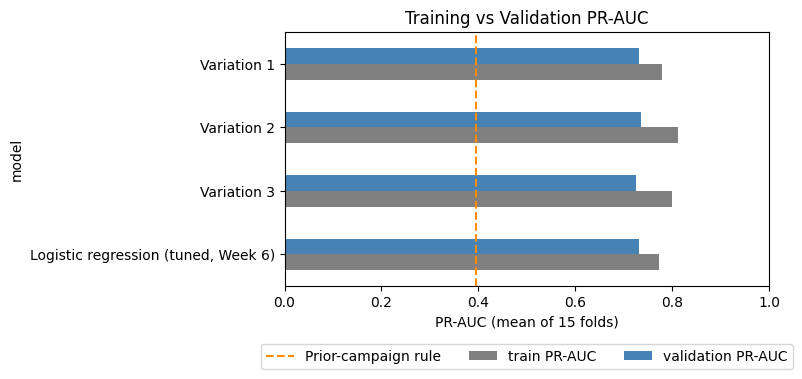

In [17]:
# Training vs validation PR-AUC, gap, fold-to-fold sd, and folds beating the tuned logistic regression
val8 = all_results8[all_results8["set"] == "Validation"].pivot(index="fold", columns="model", values="PR-AUC")
trn8 = all_results8[all_results8["set"] == "Training"].pivot(index="fold", columns="model", values="PR-AUC")

comparison8 = pd.DataFrame({
    "train PR-AUC": trn8.mean(),
    "validation PR-AUC": val8.mean(),
    "validation sd": val8.std(),
    "gap (train - validation)": trn8.mean() - val8.mean(),
    "folds beating tuned LR (of 15)": val8.gt(val8[reference_name8], axis=0).sum(),
}).loc[order8].round(3)
comparison8.loc[reference_name8, "folds beating tuned LR (of 15)"] = np.nan
print(comparison8.to_string())

# Bar chart of training vs validation PR-AUC
ax = comparison8[["train PR-AUC", "validation PR-AUC"]].iloc[::-1].plot.barh(
    figsize=(8, 4), color=["grey", "steelblue"])
ax.axvline(np.mean(rule_pr8), color="darkorange", linestyle="--", label="Prior-campaign rule")
ax.set_xlabel("PR-AUC (mean of 15 folds)"); ax.set_xlim(0, 1)
ax.set_title("Training vs Validation PR-AUC")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)
plt.tight_layout(); plt.show()

### Best model of the week

In [18]:
# Pick the variation with the highest mean validation PR-AUC
candidates8 = list(variations8)
best_name8 = comparison8.loc[candidates8, "validation PR-AUC"].idxmax()
runner_up8 = comparison8.loc[[c for c in candidates8 if c != best_name8], "validation PR-AUC"].idxmax()
diff_runner = val8[best_name8] - val8[runner_up8]
diff_lr = val8[best_name8] - val8[reference_name8]

# Compare the winner with the runner-up, the tuned logistic regression, and the prior-campaign rule
print(f"Best variation: {best_name8}")
print(f"  Validation PR-AUC {comparison8.loc[best_name8, 'validation PR-AUC']:.3f}"
      f" | gap {comparison8.loc[best_name8, 'gap (train - validation)']:.3f}")
print(f"  vs runner-up ({runner_up8}, {comparison8.loc[runner_up8, 'validation PR-AUC']:.3f}): "
      f"better on {(diff_runner > 0).sum()} of 15 folds, mean difference {diff_runner.mean():+.3f} "
      f"(fold-to-fold sd of the difference {diff_runner.std():.3f})")
print(f"  vs tuned logistic regression ({comparison8.loc[reference_name8, 'validation PR-AUC']:.3f}): "
      f"better on {(diff_lr > 0).sum()} of 15 folds, mean difference {diff_lr.mean():+.3f} "
      f"(fold-to-fold sd of the difference {diff_lr.std():.3f})")
print(f"  vs prior-campaign rule ({np.mean(rule_pr8):.3f}): "
      f"{comparison8.loc[best_name8, 'validation PR-AUC'] - np.mean(rule_pr8):+.3f}")

# Train the winner on all training rows and save it (test set not used)
MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
final8 = clone(variations8[best_name8]).fit(X8, y8)
joblib.dump({"model": final8, "features": list(X8.columns), "variation": best_name8},
            MODEL_DIR / "week8_best_model.joblib")
print("\nSaved:", MODEL_DIR / "week8_best_model.joblib")

Best variation: Variation 2
  Validation PR-AUC 0.735 | gap 0.079
  vs runner-up (Variation 1, 0.731): better on 10 of 15 folds, mean difference +0.003 (fold-to-fold sd of the difference 0.009)
  vs tuned logistic regression (0.732): better on 8 of 15 folds, mean difference +0.002 (fold-to-fold sd of the difference 0.017)
  vs prior-campaign rule (0.395): +0.340


/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalt


Saved: ../models/week8_best_model.joblib
